In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

from utils.models import * 

In [2]:
df = pd.read_csv("../data/Amazon1.0/amazon-purchases.csv")
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")


RUNNING ItemTimeBase FINISHED
RUNNING ItemKNN FINISHED
RUNNING EASE FINISHED
RUNNING MostPopular FINISHED
RUNNING RecentPopular FINISHED
RUNNING SVD FINISHED
RUNNING ItemEmbeddings FINISHED
                Precision@10  Recall@10  HitRate@10   NDCG@10
ItemTimeBase        0.105830   0.041747    0.581562  0.116357
ItemKNN             0.252178   0.092206    0.812881  0.262622
EASE                0.303262   0.116651    0.846348  0.340896
MostPopular         0.276679   0.107274    0.846769  0.297165
RecentPopular       0.244159   0.094552    0.827615  0.293572
SVD                 0.101095   0.037582    0.549989  0.109959
ItemEmbeddings      0.106230   0.042147    0.577142  0.114177


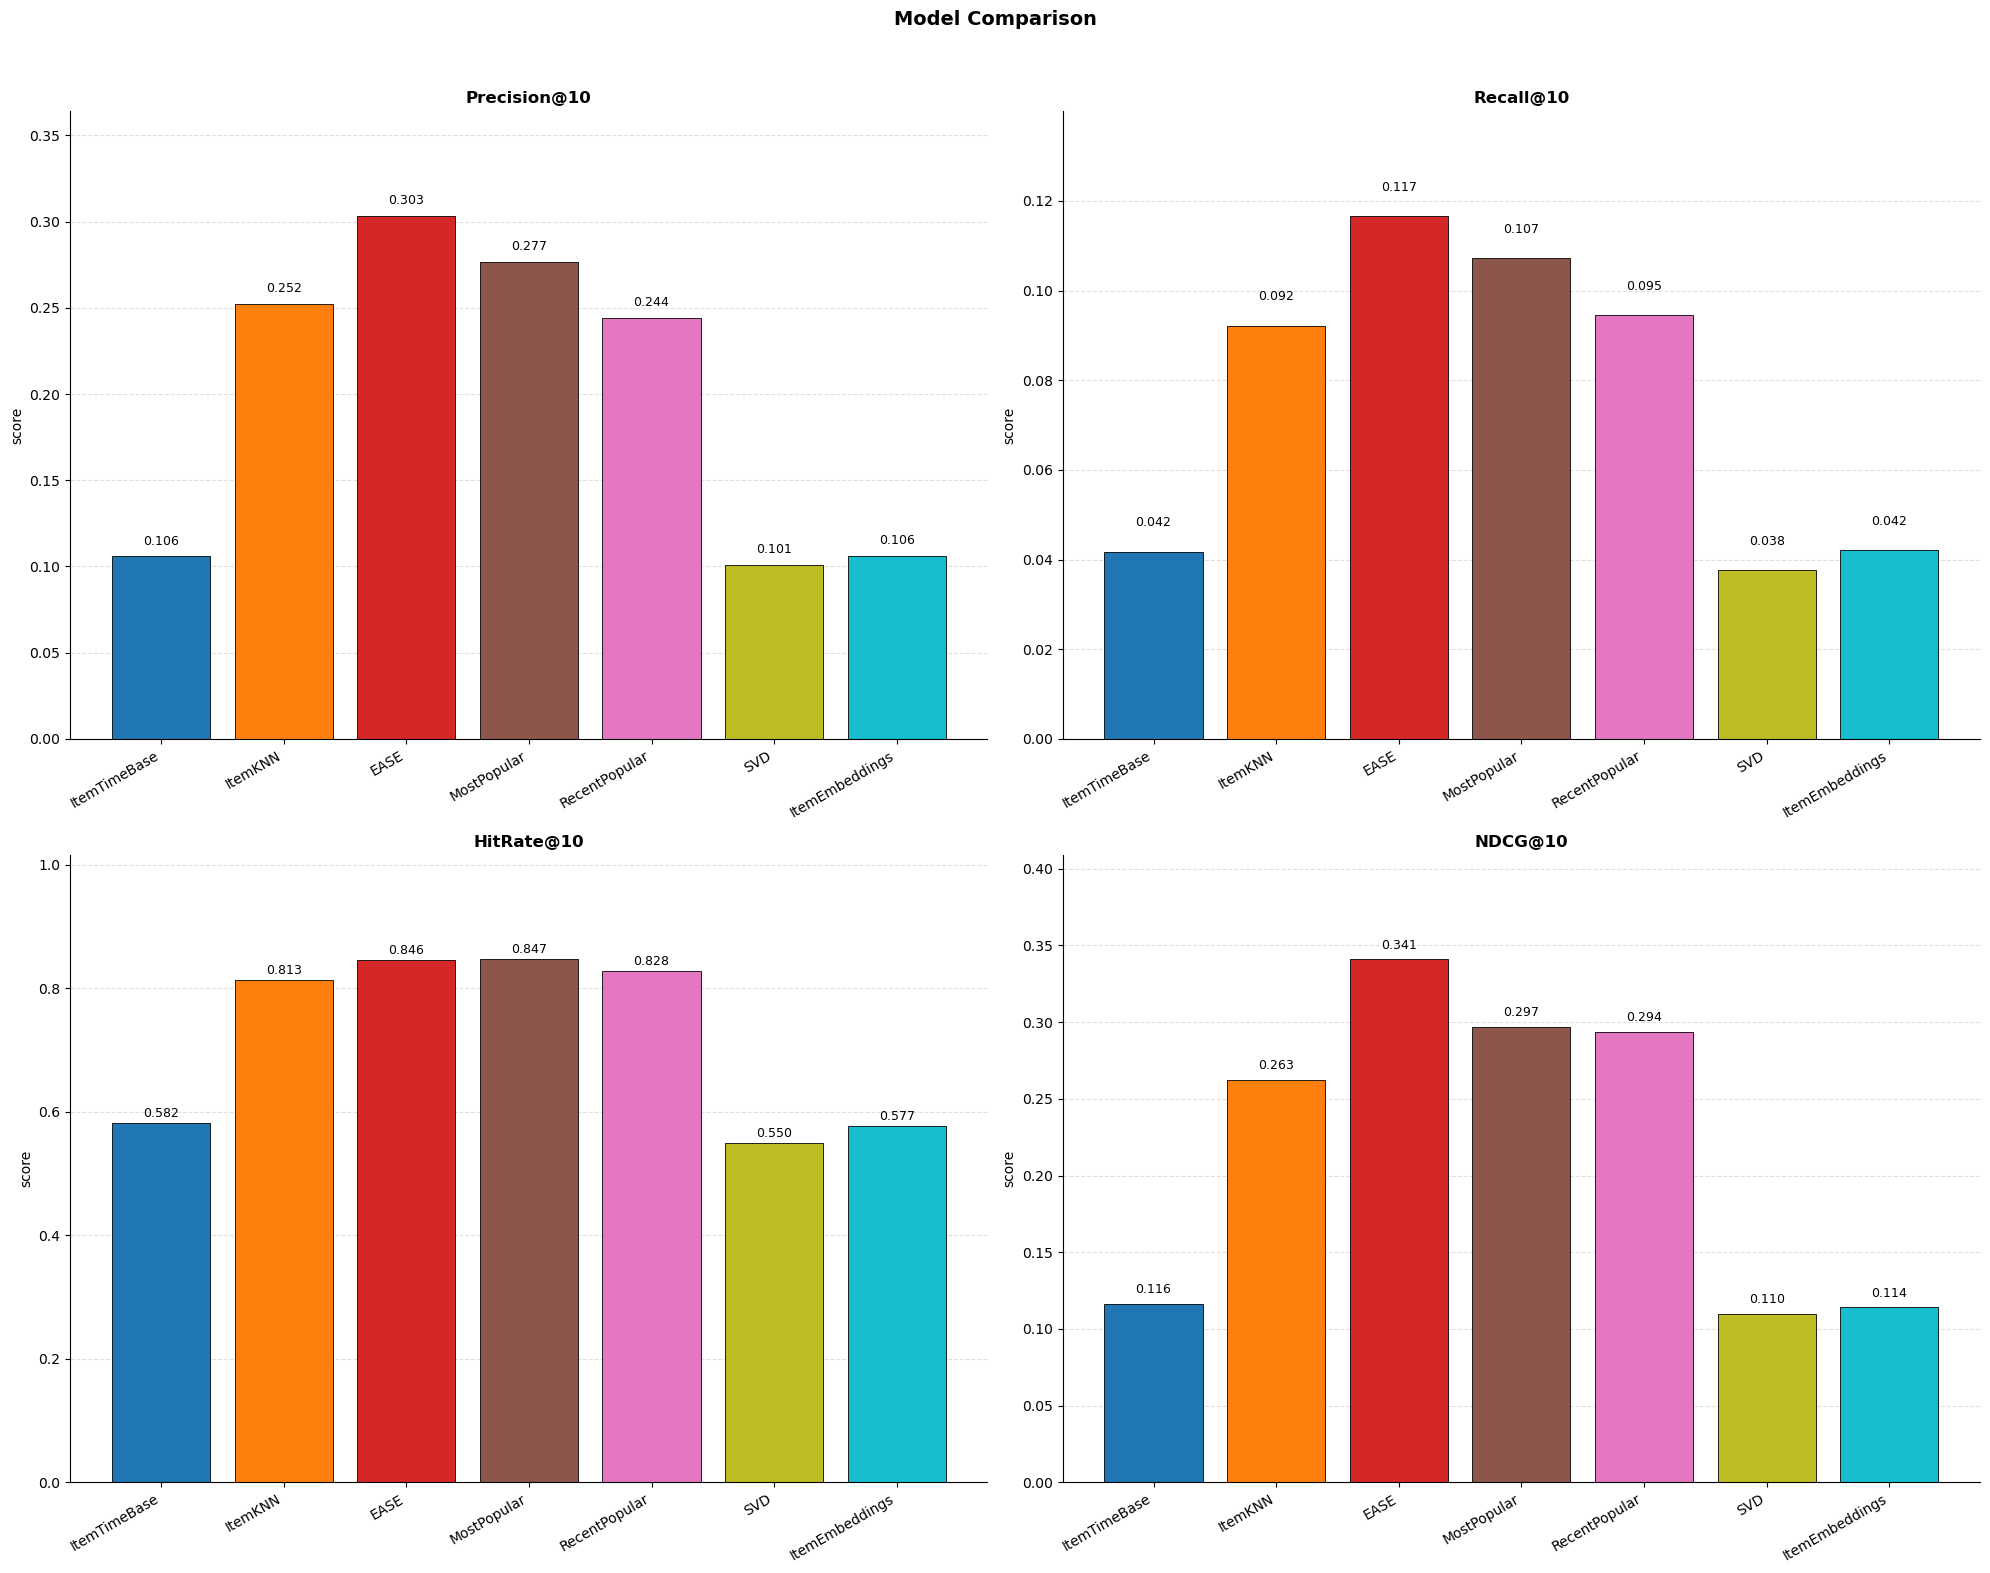

In [3]:
cmp = ModelComparator(
    models={
        "ItemTimeBase"   : ItemTimeBase(),
        "ItemKNN":         ItemKNN(k=10, n_neighbors=200),
        "EASE":            EASE(k=10, l2=200.0),
        "MostPopular":     MostPopular(k=10),
        "RecentPopular":   RecentPopular(k=10, window=0.2),
        "SVD":             SVDRecommender(k=10, latent_dim=50),
        "ItemEmbeddings" : EmbeddingAvg(),
    },
    k=10,
    split="global_time",
)
res = cmp.run(df, item_col="Category")
print(res)
cmp.plot()